### Common libraries and `mpl` settings

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import linregress, t
from cmcrameri import cm as cmc

MM = 1.0 / 25.4
Tm = 4996  # melting temperature, K

WIDTH_1COL = 90 * MM
FIGSIZE_1COL = (WIDTH_1COL, 70 * MM)
FIGSIZE_1P5COL = (135 * MM, 90 * MM)
FIGSIZE_2COL = (180 * MM, 105 * MM)

mpl.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.fallback": "stix",
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "legend.fontsize": 9,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "legend.frameon": False,
        "axes.grid": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

results_folder = Path.cwd().parent / "single_fiber" / "heat" / "results" / "TMB"

out_folder = Path.cwd() / "figures"
out_folder.mkdir(exist_ok=True)

alphas = [25, 50, 75, 100, 200, 400, 800]

alpha_colors = dict(zip(alphas, cmc.batlow(np.linspace(0.08, 0.92, len(alphas)))))

In [3]:
state_markers = {
    "W": "o",
    "he0": "s",
    "he1": "^",
    "he2": "D",
}

state_labels = {
    "W": "W",
    "he0": "He/V = 0",
    "he1": "He/V = 1",
    "he2": "He/V = 2",
}

T0 = 300.0


def read_break(run_dir):
    heat_off = pd.read_csv(
        run_dir / "heat_off.txt",
        sep=r"\s+",
    )

    if "stage" in heat_off.columns:
        rows = heat_off[heat_off["stage"] == "break"]
        stop = rows.iloc[0] if len(rows) else heat_off.iloc[0]
    else:
        stop = heat_off.iloc[0]

    return float(stop["time_ps"]), float(stop["T_cluster"])

## Data preparation from MD
Run the following extraction cells only when the complete MD calculation results are available in `single_fiber/heat/results/`. The plotting cells below use only `pp_data/`.

### Figure 2 — cluster temperature and population
Read `structure.txt` up to connectivity loss for each of the 70 trajectories. Export the original time series.

In [4]:
root = results_folder / "phi006"
seeds = range(42, 52)
state = "he2"
rows = []

for alpha in alphas:
    for seed in seeds:
        run = root / f"s{seed}" / state / f"alpha_{alpha:.1f}"
        tc, _ = read_break(run)
        d = pd.read_csv(
            run / "structure.txt",
            sep=r"\s+",
            usecols=["time_ps", "T_cluster", "Nlargest"],
        )
        d = d.loc[d.time_ps <= tc].copy()
        d["alpha"] = alpha
        d["seed"] = seed
        rows.append(d)

traces = pd.concat(rows, ignore_index=True)
pp = Path("pp_data")
pp.mkdir(exist_ok=True)
traces.to_csv(pp / "w_atom_loss.csv.gz", index=False, compression="gzip")
print(
    f"Figure 2: {len(traces)} records, {traces.groupby(['alpha', 'seed']).ngroups} trajectories"
)

Figure 2: 62608 records, 70 trajectories


### Figure 3 — connectivity-loss metrics
Read `heat_off.txt`, `heat.txt`, and `structure.txt`. Integrate deposited energy using the left-endpoint sum and save one row per simulation.

In [5]:
rows = []
cases = [
    ("W", "phi000", "he0", range(10)),
    ("he0", "phi006", "he0", range(42, 52)),
    ("he1", "phi006", "he1", range(42, 52)),
    ("he2", "phi006", "he2", range(42, 52)),
]

for state, case, he_state, seeds in cases:
    for alpha in alphas:
        for seed in seeds:
            run = results_folder / case / f"s{seed}" / he_state / f"alpha_{alpha:.1f}"
            if not (run / "heat_off.txt").exists():
                continue
            tc, Tc = read_break(run)
            h = pd.read_csv(run / "heat.txt", sep=r"\s+", usecols=["NW_box"])
            d = pd.read_csv(
                run / "structure.txt", sep=r"\s+", usecols=["time_ps", "Nheat"]
            )
            d = d[d.time_ps <= tc + 1e-6].sort_values("time_ps")
            d = d.drop_duplicates("time_ps", keep="last")
            eps_c = (
                3
                * 8.617333262e-5
                * alpha
                * np.sum(np.diff(d.time_ps.to_numpy()) * d.Nheat.to_numpy()[:-1])
                / h.NW_box.iloc[0]
            )
            rows.append((state, alpha, seed, tc, Tc, eps_c))

metrics = pd.DataFrame(rows, columns=["state", "alpha", "seed", "tc", "Tc", "eps_c"])
metrics.to_csv(pp / "connectivity_metrics.csv", index=False)
print(f"Figure 3: {len(metrics)} simulations")

Figure 3: 250 simulations


## Figures from processed data
The following cells can be run independently of the MD extraction stage.

### Figure 2

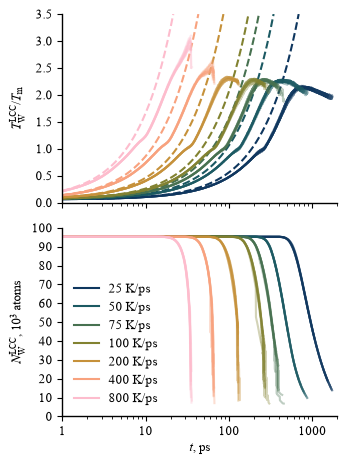

In [ ]:
traces = pd.read_csv("pp_data/w_atom_loss.csv.gz")

fig_W_cluster, (ax0, ax1) = plt.subplots(
    2,
    1,
    figsize=(WIDTH_1COL, 120 * MM),
    sharex=True,
)

for alpha in alphas:
    color = alpha_colors[alpha]

    for seed in range(42, 52):
        structure = traces.loc[traces.alpha.eq(alpha) & traces.seed.eq(seed)]

        ax0.plot(
            structure.time_ps, structure.T_cluster / Tm, color=color, lw=1.5, alpha=0.35
        )
        ax1.plot(
            structure.time_ps, structure.Nlargest / 1e3, color=color, lw=1.5, alpha=0.35
        )

    t_nominal_max = (3.5 * Tm - T0) / alpha
    t_nominal = np.geomspace(0.3, t_nominal_max, 200)
    ax0.plot(t_nominal, (T0 + alpha * t_nominal) / Tm, "--", color=color, lw=1.5)
    ax1.plot([], [], color=color, lw=1.5, label=f"{alpha} K/ps")

ax0.set_xscale("log")
ax0.set_xlim(1, 2000)
ax0.set_ylim(0, 3.5)
ax0.set_yticks([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5])
ax0.tick_params(axis="x", labelbottom=False)
ax0.set_xticks([1, 10, 100, 1000])
ax0.set_xticklabels(["1", "10", "100", "1000"])
ax0.set_ylabel(r"$T^{\rm LCC}_{\rm W}/T_{\rm m}$")


ax1.set_xscale("log")
ax1.set_xlim(1, 2000)
ax1.set_ylim(0, 100)
ax1.set_yticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
ax1.set_xlabel(r"$t$, ps")
ax1.set_xticks([1, 10, 100, 1000])
ax1.set_xticklabels(["1", "10", "100", "1000"])
ax1.set_ylabel(r"$N^{\rm LCC}_{\rm W}$, $10^3$ atoms")
ax1.legend(loc="lower left", frameon=False)

fig_W_cluster.align_ylabels()
fig_W_cluster.tight_layout()
fig_W_cluster.savefig(out_folder / "W_atom_loss.pdf", pad_inches=0.05)

plt.show()

### Figure 3

In [7]:
metrics = pd.read_csv("pp_data/connectivity_metrics.csv")
failure_df = metrics[["state", "alpha", "seed", "tc", "Tc"]].copy()
energy_df = metrics[["state", "alpha", "seed", "tc", "eps_c"]].copy()

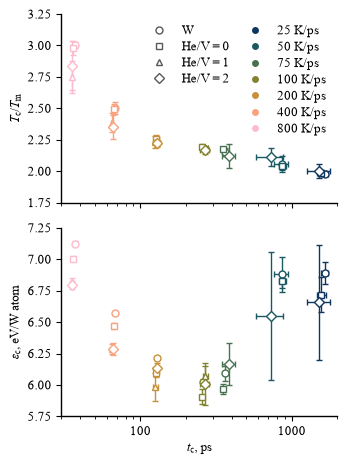

In [ ]:
fig_connectivity, (ax0, ax1) = plt.subplots(
    2,
    1,
    figsize=(WIDTH_1COL, 120 * MM),
    sharex=True,
)

for alpha in alphas:
    color = alpha_colors[alpha]
    for state, marker in state_markers.items():
        d = failure_df[failure_df.alpha.eq(alpha) & failure_df.state.eq(state)]
        e = energy_df[energy_df.alpha.eq(alpha) & energy_df.state.eq(state)]
        if d.empty or e.empty:
            continue
        ax0.errorbar(
            d.tc.mean(),
            d.Tc.mean() / Tm,
            xerr=d.tc.std(),
            yerr=d.Tc.std() / Tm,
            fmt=marker,
            ms=5,
            mfc="white",
            mec=color,
            ecolor=color,
            elinewidth=1,
            capsize=2,
            zorder=3,
        )
        ax1.errorbar(
            e.tc.mean(),
            e.eps_c.mean(),
            xerr=e.tc.std(),
            yerr=e.eps_c.std(),
            fmt=marker,
            ms=5,
            mfc="white",
            mec=color,
            ecolor=color,
            elinewidth=1,
            capsize=2,
            zorder=3,
        )

alpha_handles = [
    Line2D(
        [],
        [],
        marker="o",
        ls="none",
        ms=5,
        markerfacecolor=alpha_colors[a],
        markeredgecolor="none",
        label=f"{a} K/ps",
    )
    for a in alphas
]
state_handles = [
    Line2D(
        [],
        [],
        marker=state_markers[s],
        ls="none",
        ms=5,
        markerfacecolor="white",
        markeredgecolor="0.35",
        label=state_labels[s],
    )
    for s in state_markers
]

leg = ax0.legend(
    handles=state_handles,
    loc="upper right",
    bbox_to_anchor=(0.65, 1.0),
    labelspacing=0.35,
)
ax0.add_artist(leg)
ax0.legend(handles=alpha_handles, loc="upper right", labelspacing=0.35)

ax0.set(ylabel=r"$T_{\rm c}/T_{\rm m}$", ylim=(1.75, 3.25))
ax1.set(
    xlabel=r"$t_{\rm c}$, ps",
    ylabel=r"$\varepsilon_{\rm c}$, eV/W atom",
    ylim=(5.75, 7.25),
)
ax1.set_xscale("log")
ax1.set_xlim(30, 2000)
ax1.set_xticks([100, 1000])
ax1.set_xticklabels(["100", "1000"])
ax0.tick_params(axis="x", labelbottom=False)
ax0.set_yticks([1.75, 2.0, 2.25, 2.5, 2.75, 3, 3.25])
ax1.set_yticks([5.75, 6, 6.25, 6.5, 6.75, 7, 7.25])

fig_connectivity.align_ylabels()
fig_connectivity.tight_layout()
fig_connectivity.savefig(out_folder / "connectivity_loss.pdf", pad_inches=0.05)
plt.show()

### Connectivity-loss fits

In [10]:
alpha0 = 100.0
states = ["W", "he0", "he2"]

d = (
    failure_df[failure_df["state"].isin(states)]
    .groupby(["state", "alpha"], as_index=False)
    .agg(tc=("tc", "mean"))
)

x = np.log(d["alpha"].to_numpy() / alpha0)
y = np.log(d["tc"].to_numpy())

X = np.column_stack(
    [
        np.ones(len(d)),
        (d["state"] == "he0").astype(float),
        (d["state"] == "he2").astype(float),
        x,
    ]
)

beta = np.linalg.lstsq(X, y, rcond=None)[0]
res = y - X @ beta

dof = len(y) - X.shape[1]
s2 = np.sum(res**2) / dof
cov = s2 * np.linalg.inv(X.T @ X)

p = beta[-1]
dp = t.ppf(0.975, dof) * np.sqrt(cov[-1, -1])

print(f"p = {p:.3f} ± {dp:.3f}")
print(f"t_c ~ alpha^({p:.1f} ± {dp:.1f})")

p = -1.107 ± 0.066
t_c ~ alpha^(-1.1 ± 0.1)


In [11]:
d = failure_df.groupby("alpha", as_index=False).agg(
    tc=("tc", "mean"),
    tc_std=("tc", "std"),
    Tc=("Tc", "mean"),
    Tc_std=("Tc", "std"),
    n=("tc", "size"),
)

x = np.log(d["alpha"].to_numpy())
y = np.log(d["tc"].to_numpy())

fit_tc = linregress(x, y)
dp = t.ppf(0.975, len(d) - 2) * fit_tc.stderr

alpha = d["alpha"].to_numpy()
Tc = d["Tc"].to_numpy() / Tm

fit_Tc = linregress(alpha, Tc)
dB = t.ppf(0.975, len(d) - 2) * fit_Tc.stderr
dA = t.ppf(0.975, len(d) - 2) * fit_Tc.intercept_stderr

print(d.round(3))

print(
    f"t_c ~ alpha^p: p = {fit_tc.slope:.3f} pm {dp:.3f}, R^2 = {fit_tc.rvalue**2:.4f}"
)

print(
    f"T_c/T_m = A + B alpha: "
    f"A = {fit_Tc.intercept:.3f} pm {dA:.3f}, "
    f"B = {fit_Tc.slope:.6e} pm {dB:.6e} ps/K, "
    f"R^2 = {fit_Tc.rvalue**2:.4f}"
)

   alpha        tc   tc_std         Tc   Tc_std   n
0     25  1577.433  173.672   9935.382  176.354  30
1     50   817.750  119.197  10336.884  310.426  30
2     75   366.100   26.601  10741.888  312.085  30
3    100   261.450   11.895  10901.329  119.880  40
4    200   127.812    3.044  11168.356  182.308  40
5    400    66.150    1.241  12160.525  469.566  40
6    800    35.762    0.759  14458.180  781.312  40
t_c ~ alpha^p: p = -1.109 pm 0.143, R^2 = 0.9875
T_c/T_m = A + B alpha: A = 2.024 pm 0.056, B = 1.081446e-03 pm 1.594290e-04 ps/K, R^2 = 0.9838
